# Analyze len500 dataset

Analysis of the **scored raw dataset** (generate → score, no preference pairs): basic stats and relation between the two scores (positiveness, length).

## 1. Basic stats, relation, and plots (all responses as a whole)

Load the scored raw dataset; stack all responses and show: stats of the two scores, their Pearson correlation, score distributions, and scatter (x=positiveness, y=length).

In [2]:
import numpy as np
import pandas as pd
from datasets import load_dataset
from scipy import stats

# Config: scored raw dataset (from build_dataset.sh with max_new_tokens=500)
USER_ID = "mxcui"
NUM_RESPONSES = 2
MAX_NEW_TOKENS = 512
EXP_TAG = f"n{NUM_RESPONSES}-len{MAX_NEW_TOKENS}-random"
RAW_DATASET_ID = f"{USER_ID}/gpt2-imdb-raw-{EXP_TAG}"

ds = load_dataset(RAW_DATASET_ID, split="train")
df = ds.to_pandas()

# Stack all response scores into single arrays (no grouping)
pos_cols = sorted([c for c in df.columns if c.startswith("positiveness_") and "_z_" not in c], key=lambda x: int(x.split("_")[1]))
len_cols = sorted([c for c in df.columns if c.startswith("length_")], key=lambda x: int(x.split("_")[1]))
pos_all = np.concatenate([df[c].values for c in pos_cols])
len_all = np.concatenate([df[c].values for c in len_cols])
n_scores = len(pos_all)
# Z-score columns (if present: positiveness_z_{i}, conciseness_z_{i})
pos_z_cols = sorted([c for c in df.columns if c.startswith("positiveness_z_")], key=lambda x: int(x.split("_")[-1]))
conc_z_cols = sorted([c for c in df.columns if c.startswith("conciseness_z_")], key=lambda x: int(x.split("_")[-1]))
has_z = len(pos_z_cols) == len(pos_cols) and len(conc_z_cols) == len(len_cols)
if has_z:
    pos_z_all = np.concatenate([df[c].values for c in pos_z_cols])
    conc_z_all = np.concatenate([df[c].values for c in conc_z_cols])
else:
    pos_z_all = conc_z_all = None

print("Dataset:", RAW_DATASET_ID)
print("Shape:", df.shape)
print("Total score values (all responses):", n_scores)
print()

Dataset: mxcui/gpt2-imdb-raw-n2-len512-random
Shape: (24895, 13)
Total score values (all responses): 49790



In [3]:
# Stats of the two scores (all responses as a whole)
print("=" * 60)
print("Stats (positiveness, length)")
print("=" * 60)
print("Positiveness:  count=%d  mean=%.4f  std=%.4f  min=%.4f  max=%.4f" % (n_scores, pos_all.mean(), pos_all.std(), pos_all.min(), pos_all.max()))
print("Length:        count=%d  mean=%.2f  std=%.2f  min=%d  max=%d" % (n_scores, len_all.mean(), len_all.std(), int(len_all.min()), int(len_all.max())))
print()
# Relation: Pearson
r, pval = stats.pearsonr(pos_all, len_all)
print("Pearson(positiveness, length):  r = %.4f,  p = %.4e" % (r, pval))
print()
if has_z:
    print("Stats (normalized: positiveness_z, conciseness_z)")
    print("=" * 60)
    print("Positiveness_z: count=%d  mean=%.4f  std=%.4f  min=%.4f  max=%.4f" % (n_scores, pos_z_all.mean(), pos_z_all.std(), pos_z_all.min(), pos_z_all.max()))
    print("Conciseness_z:  count=%d  mean=%.4f  std=%.4f  min=%.4f  max=%.4f" % (n_scores, conc_z_all.mean(), conc_z_all.std(), conc_z_all.min(), conc_z_all.max()))
    print()
    r_z, pval_z = stats.pearsonr(pos_z_all, conc_z_all)
    print("Pearson(positiveness_z, conciseness_z):  r = %.4f,  p = %.4e" % (r_z, pval_z))
    print()

Stats (positiveness, length)
Positiveness:  count=49790  mean=0.6230  std=0.4346  min=0.0027  max=0.9964
Length:        count=49790  mean=141.86  std=123.11  min=3  max=512

Pearson(positiveness, length):  r = -0.0382,  p = 1.5935e-17

Stats (normalized: positiveness_z, conciseness_z)
Positiveness_z: count=49790  mean=-0.0000  std=1.0000  min=-1.4270  max=0.8592
Conciseness_z:  count=49790  mean=-0.0000  std=1.0000  min=-3.0066  max=1.1280

Pearson(positiveness_z, conciseness_z):  r = 0.0382,  p = 1.5935e-17



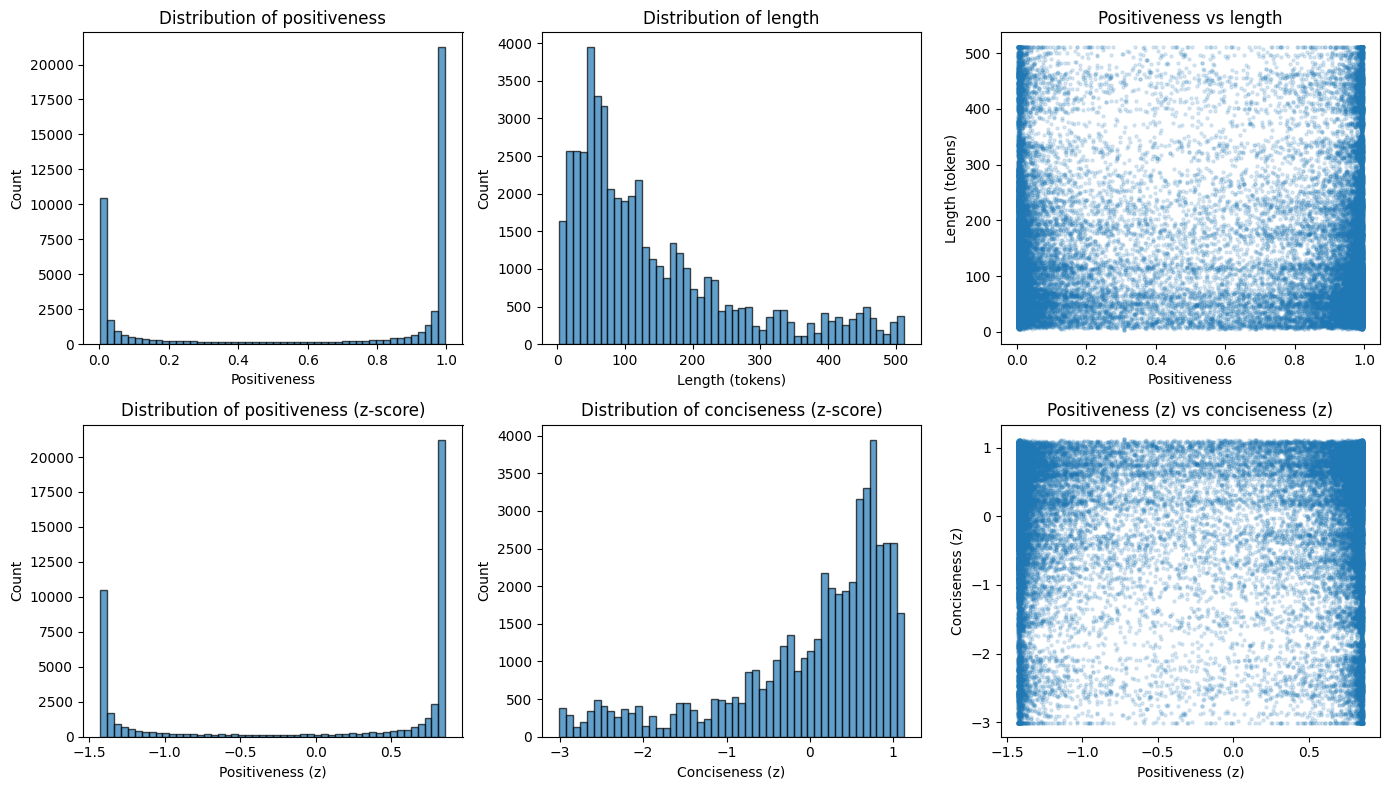

In [4]:
# Distribution of the two scores + scatter; add normalized (z) row if present
import matplotlib.pyplot as plt

n_rows = 2 if has_z else 1
fig, axes = plt.subplots(n_rows, 3, figsize=(14, 4 * n_rows))
if n_rows == 1:
    axes = axes.reshape(1, -1)
axes[0, 0].hist(pos_all, bins=50, edgecolor="black", alpha=0.7)
axes[0, 0].set_xlabel("Positiveness")
axes[0, 0].set_ylabel("Count")
axes[0, 0].set_title("Distribution of positiveness")
axes[0, 1].hist(len_all, bins=50, edgecolor="black", alpha=0.7)
axes[0, 1].set_xlabel("Length (tokens)")
axes[0, 1].set_ylabel("Count")
axes[0, 1].set_title("Distribution of length")
axes[0, 2].scatter(pos_all, len_all, alpha=0.15, s=5)
axes[0, 2].set_xlabel("Positiveness")
axes[0, 2].set_ylabel("Length (tokens)")
axes[0, 2].set_title("Positiveness vs length")
if has_z:
    axes[1, 0].hist(pos_z_all, bins=50, edgecolor="black", alpha=0.7)
    axes[1, 0].set_xlabel("Positiveness (z)")
    axes[1, 0].set_ylabel("Count")
    axes[1, 0].set_title("Distribution of positiveness (z-score)")
    axes[1, 1].hist(conc_z_all, bins=50, edgecolor="black", alpha=0.7)
    axes[1, 1].set_xlabel("Conciseness (z)")
    axes[1, 1].set_ylabel("Count")
    axes[1, 1].set_title("Distribution of conciseness (z-score)")
    axes[1, 2].scatter(pos_z_all, conc_z_all, alpha=0.15, s=5)
    axes[1, 2].set_xlabel("Positiveness (z)")
    axes[1, 2].set_ylabel("Conciseness (z)")
    axes[1, 2].set_title("Positiveness (z) vs conciseness (z)")
plt.tight_layout()
plt.show()

## 2. Distribution of score differences (response_0 vs response_1)

Per-prompt difference between the two generated responses: **positiveness** (response_1 − response_0) and **length** (response_1 − response_0; length as proxy for conciseness).

Score differences (response_1 − response_0)
  Positiveness:  mean= 0.0018  std=0.5581  min=-0.9929  max= 0.9930
  Length:        mean=-0.09  std=154.77  min=-508.0  max= 505.0
  Positiveness_z: mean= 0.0042  std=1.2839  min=-2.2843  max= 2.2847
  Conciseness_z:  mean= 0.0007  std=1.2572  min=-4.1021  max= 4.1265



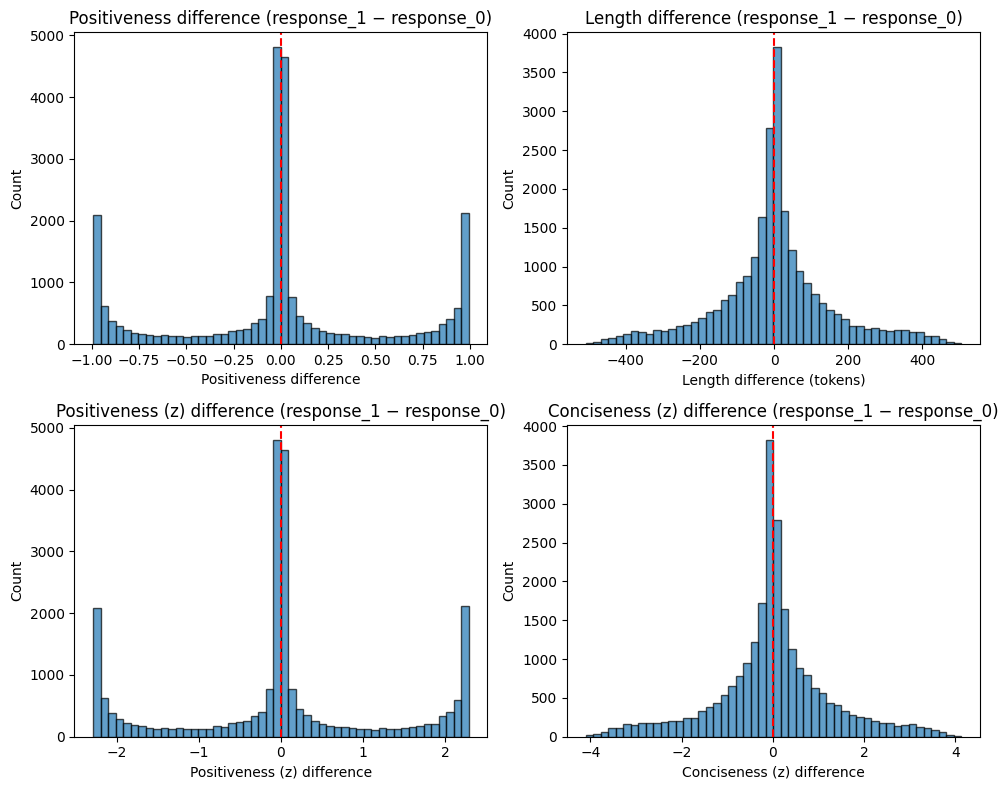

In [5]:
# Require at least two responses per prompt
assert len(pos_cols) >= 2 and len(len_cols) >= 2, "Need at least 2 responses (positiveness_0/1, length_0/1)"

pos_diff = (df["positiveness_1"] - df["positiveness_0"]).values
len_diff = (df["length_1"] - df["length_0"]).values.astype(float)

print("Score differences (response_1 − response_0)")
print("  Positiveness:  mean=% .4f  std=%.4f  min=% .4f  max=% .4f" % (pos_diff.mean(), pos_diff.std(), pos_diff.min(), pos_diff.max()))
print("  Length:        mean=% .2f  std=%.2f  min=% .1f  max=% .1f" % (len_diff.mean(), len_diff.std(), len_diff.min(), len_diff.max()))
if has_z:
    pos_z_diff = (df["positiveness_z_1"] - df["positiveness_z_0"]).values
    conc_z_diff = (df["conciseness_z_1"] - df["conciseness_z_0"]).values
    print("  Positiveness_z: mean=% .4f  std=%.4f  min=% .4f  max=% .4f" % (pos_z_diff.mean(), pos_z_diff.std(), pos_z_diff.min(), pos_z_diff.max()))
    print("  Conciseness_z:  mean=% .4f  std=%.4f  min=% .4f  max=% .4f" % (conc_z_diff.mean(), conc_z_diff.std(), conc_z_diff.min(), conc_z_diff.max()))
print()

n_plot = 4 if has_z else 2
fig, axes = plt.subplots(1 if not has_z else 2, 2, figsize=(10, 4 if not has_z else 8))
if has_z:
    axes = axes.flatten()
else:
    axes = list(axes)
axes[0].hist(pos_diff, bins=50, edgecolor="black", alpha=0.7)
axes[0].axvline(0, color="red", linestyle="--")
axes[0].set_xlabel("Positiveness difference")
axes[0].set_ylabel("Count")
axes[0].set_title("Positiveness difference (response_1 − response_0)")
axes[1].hist(len_diff, bins=50, edgecolor="black", alpha=0.7)
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_xlabel("Length difference (tokens)")
axes[1].set_ylabel("Count")
axes[1].set_title("Length difference (response_1 − response_0)")
if has_z:
    axes[2].hist(pos_z_diff, bins=50, edgecolor="black", alpha=0.7)
    axes[2].axvline(0, color="red", linestyle="--")
    axes[2].set_xlabel("Positiveness (z) difference")
    axes[2].set_ylabel("Count")
    axes[2].set_title("Positiveness (z) difference (response_1 − response_0)")
    axes[3].hist(conc_z_diff, bins=50, edgecolor="black", alpha=0.7)
    axes[3].axvline(0, color="red", linestyle="--")
    axes[3].set_xlabel("Conciseness (z) difference")
    axes[3].set_ylabel("Count")
    axes[3].set_title("Conciseness (z) difference (response_1 − response_0)")
plt.tight_layout()
plt.show()

## 3. Figure 2-style: Preference distributions (chosen vs rejected by group)

Load the **preference dataset** `{USER_ID}/gpt2-imdb-preference-ALPHA{ALPHA}-len{MAX_NEW_TOKENS}-random`, score chosen/rejected with the gold (DistilBERT) scorer and normalized_length, then plot KDEs of **sentiment** (positiveness) and **conciseness proxy** (normalized_length) for chosen vs rejected by group.

Preference dataset: mxcui/gpt2-imdb-preference-ALPHA1.0-len512-random


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loaded 24,720 rows. Minority: 4823 pairs, Majority: 19897 pairs


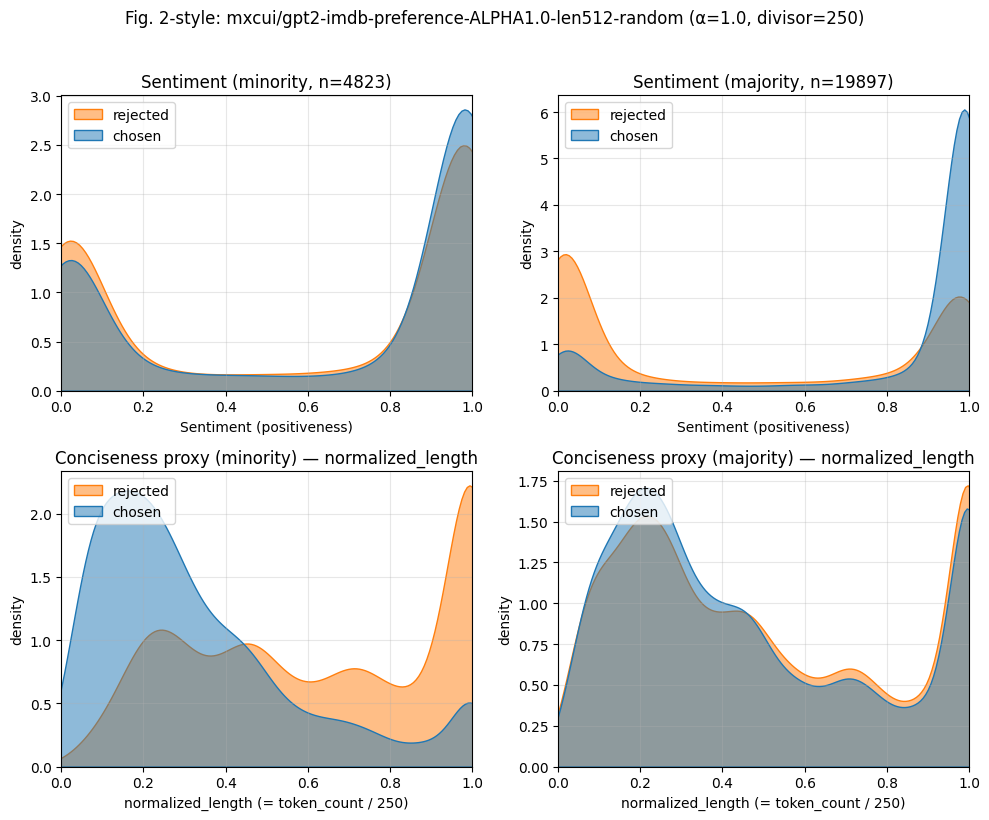

In [16]:
# Preference dataset and gold scorer for Fig. 2 and RM calibration
ALPHA = 1.0
DIVISOR = 250
SCORER_MAX_LEN = 512
BATCH_SIZE = 32
import torch
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification

PREF_DATASET_ID = f"{USER_ID}/gpt2-imdb-preference-ALPHA{ALPHA}-len{MAX_NEW_TOKENS}-random"
print("Preference dataset:", PREF_DATASET_ID)

# Gold scorer (DistilBERT) for positiveness; normalized_length from token count
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
GOLD_MODEL = "lvwerra/distilbert-imdb"
gold_tok = AutoTokenizer.from_pretrained(GOLD_MODEL)
gold_rm = AutoModelForSequenceClassification.from_pretrained(GOLD_MODEL).to(device)
gold_rm.eval()
pos_id = gold_rm.config.label2id["POSITIVE"]

def score_texts(texts, batch_size=BATCH_SIZE):
    pos_all, nlen_all = [], []
    with torch.no_grad():
        for i in range(0, len(texts), batch_size):
            batch = texts[i : i + batch_size]
            enc = gold_tok(batch, padding=True, truncation=True, max_length=SCORER_MAX_LEN, return_tensors="pt").to(device)
            out = gold_rm(input_ids=enc["input_ids"], attention_mask=enc["attention_mask"])
            probs = torch.softmax(out.logits, dim=-1)
            pos_all.extend(probs[:, pos_id].float().cpu().tolist())
            nlen_all.extend(torch.clamp(enc["attention_mask"].sum(dim=-1).float() / DIVISOR, 0.0, 1.0).cpu().tolist())
    return np.array(pos_all, dtype=np.float32), np.array(nlen_all, dtype=np.float32)

# Load preference dataset and build by_group (chosen / rejected per group_id)
pref_ds = load_dataset(PREF_DATASET_ID, split="train")
for col in ("chosen", "rejected", "group_id"):
    if col not in pref_ds.column_names:
        raise ValueError(f"Preference dataset must have column '{col}'")
by_group = {0: {"chosen": [], "rejected": []}, 1: {"chosen": [], "rejected": []}}
for ex in pref_ds:
    gid = int(ex["group_id"])
    if gid not in by_group:
        by_group[gid] = {"chosen": [], "rejected": []}
    by_group[gid]["chosen"].append(ex["chosen"])
    by_group[gid]["rejected"].append(ex["rejected"])
print(f"Loaded {len(pref_ds):,} rows. Minority: {len(by_group[0]['chosen'])} pairs, Majority: {len(by_group[1]['chosen'])} pairs")

# Score chosen and rejected per group → fig2 (for Fig. 2 plot and RM calibration)
fig2 = {}
for gid, gname in [(0, "minority"), (1, "majority")]:
    pos_c, nlen_c = score_texts(by_group[gid]["chosen"])
    pos_r, nlen_r = score_texts(by_group[gid]["rejected"])
    fig2[gname] = {"pos_chosen": pos_c, "pos_rejected": pos_r, "nlen_chosen": nlen_c, "nlen_rejected": nlen_r, "n": len(pos_c)}

# Figure 2-style: chosen vs rejected by group
import matplotlib.pyplot as plt
import seaborn as sns
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
C_CHOSEN, C_REJECTED = "C0", "C1"
ax = axes[0, 0]
sns.kdeplot(x=fig2["minority"]["pos_rejected"], ax=ax, color=C_REJECTED, label="rejected", fill=True, alpha=0.5)
sns.kdeplot(x=fig2["minority"]["pos_chosen"], ax=ax, color=C_CHOSEN, label="chosen", fill=True, alpha=0.5)
ax.set_xlim(0, 1); ax.set_ylim(0, None); ax.set_xlabel("Sentiment (positiveness)"); ax.set_ylabel("density")
ax.set_title(f"Sentiment (minority, n={fig2['minority']['n']})"); ax.legend(loc="upper left"); ax.grid(True, alpha=0.3)
ax = axes[0, 1]
sns.kdeplot(x=fig2["majority"]["pos_rejected"], ax=ax, color=C_REJECTED, label="rejected", fill=True, alpha=0.5)
sns.kdeplot(x=fig2["majority"]["pos_chosen"], ax=ax, color=C_CHOSEN, label="chosen", fill=True, alpha=0.5)
ax.set_xlim(0, 1); ax.set_ylim(0, None); ax.set_xlabel("Sentiment (positiveness)"); ax.set_ylabel("density")
ax.set_title(f"Sentiment (majority, n={fig2['majority']['n']})"); ax.legend(loc="upper left"); ax.grid(True, alpha=0.3)
ax = axes[1, 0]
sns.kdeplot(x=fig2["minority"]["nlen_rejected"], ax=ax, color=C_REJECTED, label="rejected", fill=True, alpha=0.5)
sns.kdeplot(x=fig2["minority"]["nlen_chosen"], ax=ax, color=C_CHOSEN, label="chosen", fill=True, alpha=0.5)
ax.set_xlim(0, 1); ax.set_ylim(0, None); ax.set_xlabel(f"normalized_length (= token_count / {DIVISOR})"); ax.set_ylabel("density")
ax.set_title("Conciseness proxy (minority) — normalized_length"); ax.legend(loc="upper left"); ax.grid(True, alpha=0.3)
ax = axes[1, 1]
sns.kdeplot(x=fig2["majority"]["nlen_rejected"], ax=ax, color=C_REJECTED, label="rejected", fill=True, alpha=0.5)
sns.kdeplot(x=fig2["majority"]["nlen_chosen"], ax=ax, color=C_CHOSEN, label="chosen", fill=True, alpha=0.5)
ax.set_xlim(0, 1); ax.set_ylim(0, None); ax.set_xlabel(f"normalized_length (= token_count / {DIVISOR})"); ax.set_ylabel("density")
ax.set_title("Conciseness proxy (majority) — normalized_length"); ax.legend(loc="upper left"); ax.grid(True, alpha=0.3)
fig.suptitle(f"Fig. 2-style: {PREF_DATASET_ID} (α={ALPHA}, divisor={DIVISOR})", y=1.02)
plt.tight_layout()
plt.show()

## RM calibration (len512)

Sample **chosen** responses only (one per prompt: the response with higher oracle score for that row’s group). Plot:

1. **Raw scores:** Oracle positiveness and conciseness (from gold scorer), majority/minority/vanilla RM predictions — for minority and majority samples.
2. **Normalized scores:** Oracle z-scores computed from the scored arrays; RM normalized from mean/std in `calibration/mxcui_gpt2-imdb-preference-ALPHA1.0-len512-random.json`.

In [17]:
# Use preference dataset: chosen texts and oracle scores from fig2 (section 3)
CALIB_SAMPLE = 2000
CALIB_SEED = 44

min_data = {
    "texts": by_group[0]["chosen"],
    "positiveness": fig2["minority"]["pos_chosen"],
    "conciseness": 1.0 - fig2["minority"]["nlen_chosen"],
}
maj_data = {
    "texts": by_group[1]["chosen"],
    "positiveness": fig2["majority"]["pos_chosen"],
    "conciseness": 1.0 - fig2["majority"]["nlen_chosen"],
}
# Oracle z-scores (preference dataset has no precomputed z; compute from scored arrays)
def zscore(x):
    x = np.asarray(x, dtype=np.float64)
    m, s = x.mean(), x.std()
    return (x - m) / s if s > 0 else np.zeros_like(x)
min_data["positiveness_z"] = zscore(min_data["positiveness"])
min_data["conciseness_z"] = zscore(min_data["conciseness"])
maj_data["positiveness_z"] = zscore(maj_data["positiveness"])
maj_data["conciseness_z"] = zscore(maj_data["conciseness"])

def cap_sample(data, n, seed=CALIB_SEED):
    if len(data["texts"]) <= n:
        return data
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(data["texts"]), size=n, replace=False)
    return {
        "texts": [data["texts"][i] for i in idx],
        "positiveness": data["positiveness"][idx],
        "conciseness": data["conciseness"][idx],
        "positiveness_z": data["positiveness_z"][idx],
        "conciseness_z": data["conciseness_z"][idx],
    }

min_data = cap_sample(min_data, CALIB_SAMPLE)
maj_data = cap_sample(maj_data, CALIB_SAMPLE)
print(f"Minority samples: {len(min_data['texts'])}, Majority samples: {len(maj_data['texts'])}")

Minority samples: 2000, Majority samples: 2000


In [18]:
import json
import os
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# Calibration JSON for len512 (reward_model_params: mean, std per model)
CALIB_LEN512 = os.path.join("calibration", "mxcui_gpt2-imdb-preference-ALPHA1.0-len512-random.json")
if not os.path.exists(CALIB_LEN512):
    CALIB_LEN512 = os.path.join("..", "calibration", "mxcui_gpt2-imdb-preference-ALPHA1.0-len512-random.json")
with open(CALIB_LEN512) as f:
    calib = json.load(f)

# Hub IDs from calibration (preference_dataset points to len512)
rp = calib["reward_model_params"]
# Infer model IDs (keys are full hub IDs)
VANILLA_ID = next(k for k in rp if rp[k].get("rm_type") == "vanilla")
RM_MIN_ID = next(k for k in rp if rp[k].get("group") == "minority")
RM_MAJ_ID = next(k for k in rp if rp[k].get("group") == "majority")
RM_MAX_LEN = 256
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 32

print("Loading RMs:", VANILLA_ID, RM_MIN_ID, RM_MAJ_ID)
rm_vanilla = AutoModelForSequenceClassification.from_pretrained(VANILLA_ID).to(device)
rm_min = AutoModelForSequenceClassification.from_pretrained(RM_MIN_ID).to(device)
rm_maj = AutoModelForSequenceClassification.from_pretrained(RM_MAJ_ID).to(device)
rm_vanilla.eval()
rm_min.eval()
rm_maj.eval()
tok = AutoTokenizer.from_pretrained(RM_MAJ_ID)
if tok.pad_token is None:
    tok.pad_token = tok.eos_token

Loading RMs: mxcui/vanilla-imdb-reward-ALPHA1.0-len512 mxcui/maxmin-imdb-reward-ALPHA1.0-len512-minority mxcui/maxmin-imdb-reward-ALPHA1.0-len512-majority


Loading weights:   0%|          | 0/149 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/149 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/149 [00:00<?, ?it/s]

In [12]:
def rm_logits(texts, model, batch_size=BATCH_SIZE):
    out = []
    with torch.no_grad():
        for i in range(0, len(texts), batch_size):
            batch = texts[i : i + batch_size]
            enc = tok(batch, padding=True, truncation=True, max_length=RM_MAX_LEN, return_tensors="pt").to(device)
            logit = model(**enc).logits.squeeze(-1)
            out.extend(logit.float().cpu().tolist())
    return np.array(out, dtype=np.float32)

# Score minority and majority texts with all three RMs
min_vanilla = rm_logits(min_data["texts"], rm_vanilla)
min_rm_min  = rm_logits(min_data["texts"], rm_min)
min_rm_maj  = rm_logits(min_data["texts"], rm_maj)
maj_vanilla = rm_logits(maj_data["texts"], rm_vanilla)
maj_rm_min  = rm_logits(maj_data["texts"], rm_min)
maj_rm_maj  = rm_logits(maj_data["texts"], rm_maj)

# Normalize RM scores using mean/std from calibration JSON
def normalize_rm(scores, hub_id):
    params = calib["reward_model_params"].get(hub_id, {})
    m, s = params.get("mean", 0.0), params.get("std", 1.0)
    return (scores - m) / s if s else scores

min_vanilla_n = normalize_rm(min_vanilla, VANILLA_ID)
min_rm_min_n  = normalize_rm(min_rm_min, RM_MIN_ID)
min_rm_maj_n  = normalize_rm(min_rm_maj, RM_MAJ_ID)
maj_vanilla_n = normalize_rm(maj_vanilla, VANILLA_ID)
maj_rm_min_n  = normalize_rm(maj_rm_min, RM_MIN_ID)
maj_rm_maj_n  = normalize_rm(maj_rm_maj, RM_MAJ_ID)

print("Raw RM stats (minority texts): vanilla mean=%.4f, minority RM mean=%.4f, majority RM mean=%.4f" % (min_vanilla.mean(), min_rm_min.mean(), min_rm_maj.mean()))
print("Raw RM stats (majority texts): vanilla mean=%.4f, minority RM mean=%.4f, majority RM mean=%.4f" % (maj_vanilla.mean(), maj_rm_min.mean(), maj_rm_maj.mean()))

Raw RM stats (minority texts): vanilla mean=0.5801, minority RM mean=0.1815, majority RM mean=-0.3543
Raw RM stats (majority texts): vanilla mean=0.5766, minority RM mean=0.1057, majority RM mean=-0.3476


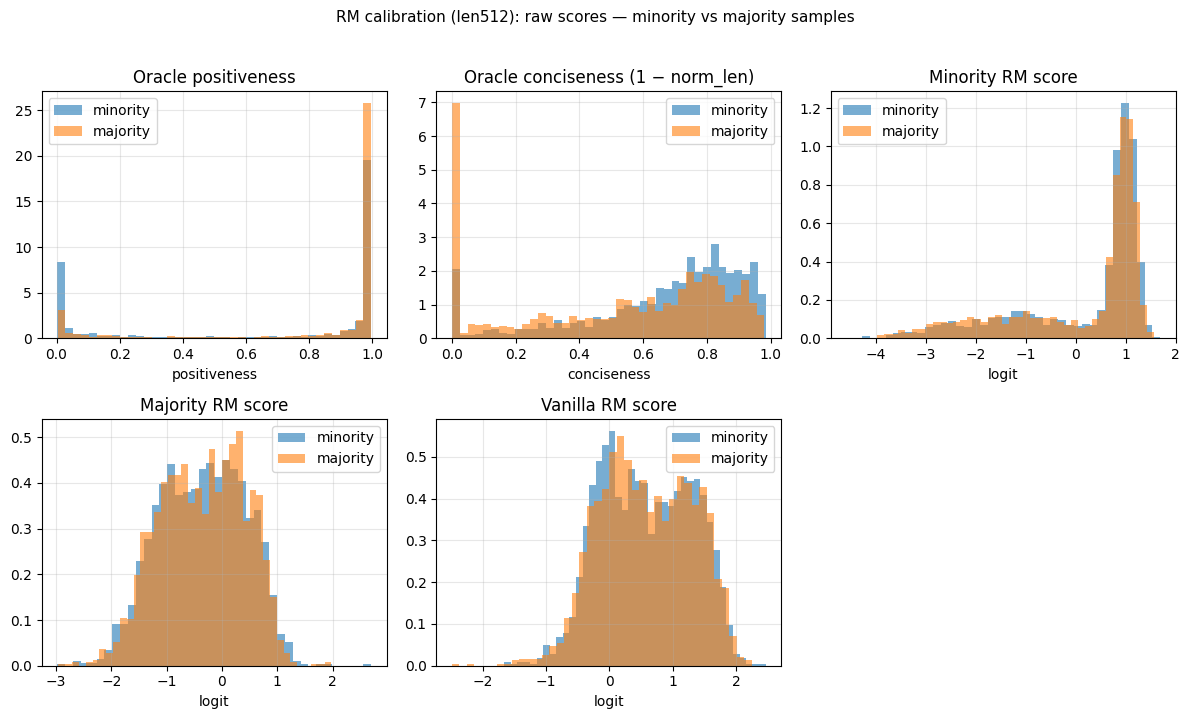

In [19]:
import matplotlib.pyplot as plt

# Raw scores: oracle positiveness, oracle conciseness, minority RM, majority RM, vanilla
C_MIN, C_MAJ = "tab:blue", "tab:orange"
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
axes = axes.flatten()

def plot_pair(ax, min_vals, maj_vals, title, xlabel):
    ax.hist(min_vals, bins=40, density=True, alpha=0.6, color=C_MIN, label="minority")
    ax.hist(maj_vals, bins=40, density=True, alpha=0.6, color=C_MAJ, label="majority")
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.legend()
    ax.grid(True, alpha=0.3)

plot_pair(axes[0], min_data["positiveness"], maj_data["positiveness"], "Oracle positiveness", "positiveness")
plot_pair(axes[1], min_data["conciseness"], maj_data["conciseness"], "Oracle conciseness (1 − norm_len)", "conciseness")
plot_pair(axes[2], min_rm_min, maj_rm_min, "Minority RM score", "logit")
plot_pair(axes[3], min_rm_maj, maj_rm_maj, "Majority RM score", "logit")
plot_pair(axes[4], min_vanilla, maj_vanilla, "Vanilla RM score", "logit")
axes[5].axis("off")
fig.suptitle("RM calibration (len512): raw scores — minority vs majority samples", fontsize=11, y=1.02)
plt.tight_layout()
plt.show()

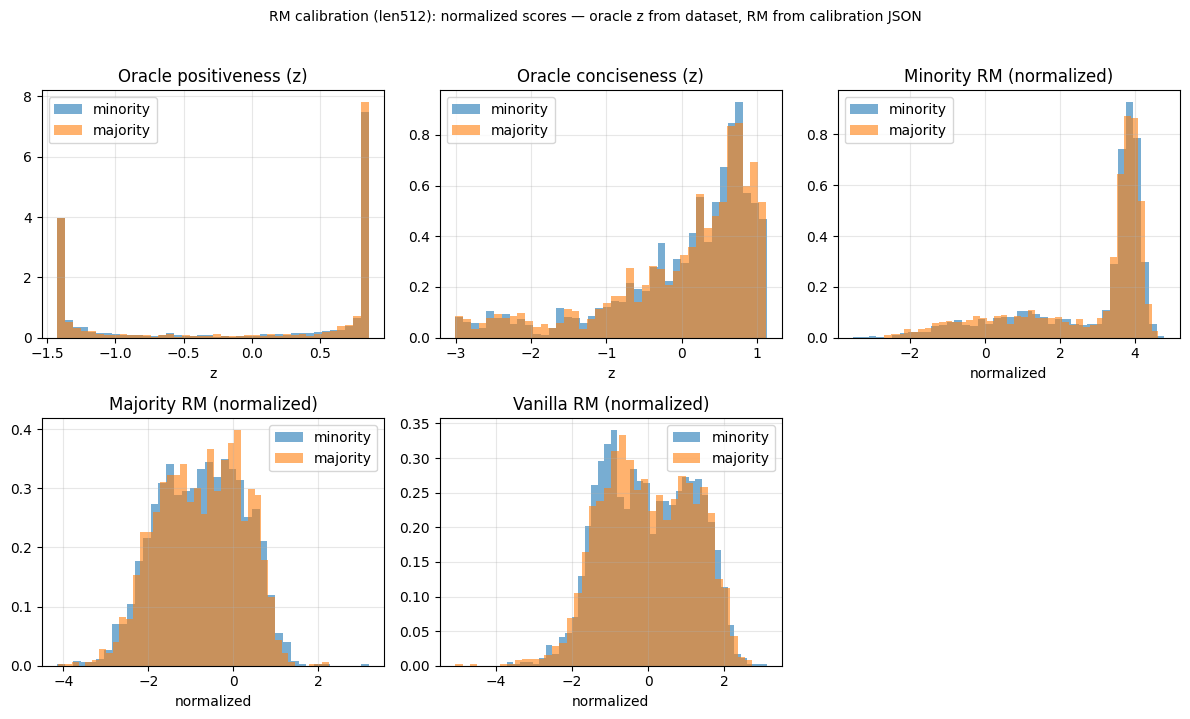

In [14]:
# Normalized scores: oracle z (computed from scored arrays), RM normalized from calibration JSON
fig2_plot, axes2 = plt.subplots(2, 3, figsize=(12, 7))
axes2 = axes2.flatten()
plot_pair(axes2[0], min_data["positiveness_z"], maj_data["positiveness_z"], "Oracle positiveness (z)", "z")
plot_pair(axes2[1], min_data["conciseness_z"], maj_data["conciseness_z"], "Oracle conciseness (z)", "z")
plot_pair(axes2[2], min_rm_min_n, maj_rm_min_n, "Minority RM (normalized)", "normalized")
plot_pair(axes2[3], min_rm_maj_n, maj_rm_maj_n, "Majority RM (normalized)", "normalized")
plot_pair(axes2[4], min_vanilla_n, maj_vanilla_n, "Vanilla RM (normalized)", "normalized")
axes2[5].axis("off")
fig2_plot.suptitle("RM calibration (len512): normalized scores — oracle z from scored arrays, RM from calibration JSON", fontsize=10, y=1.02)
plt.tight_layout()
plt.show()

## 4. Conciseness and positiveness: vanilla vs maxmin PPO policies

Load evaluation datasets for **vanilla** and **maxmin** PPO policies (generated by `evaluate_ppo_policy.sh`). If they include positiveness and length/conciseness scores, compare mean **positiveness** and **conciseness** (normalized length) between the two policies. If only `prompt` and `completion` exist, score them in-notebook with the same sentiment model and length divisor as above.

Conciseness and positiveness: vanilla vs maxmin PPO policies
 method     n  mean_positiveness  std_positiveness  mean_conciseness  std_conciseness
vanilla 24872           0.974293          0.117602          0.927381         0.027812
 maxmin 24872           0.981172          0.097649          0.846829         0.067013



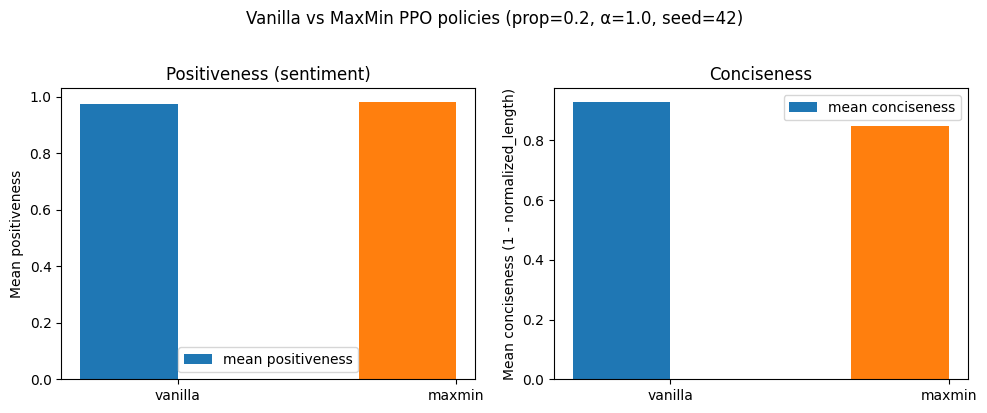

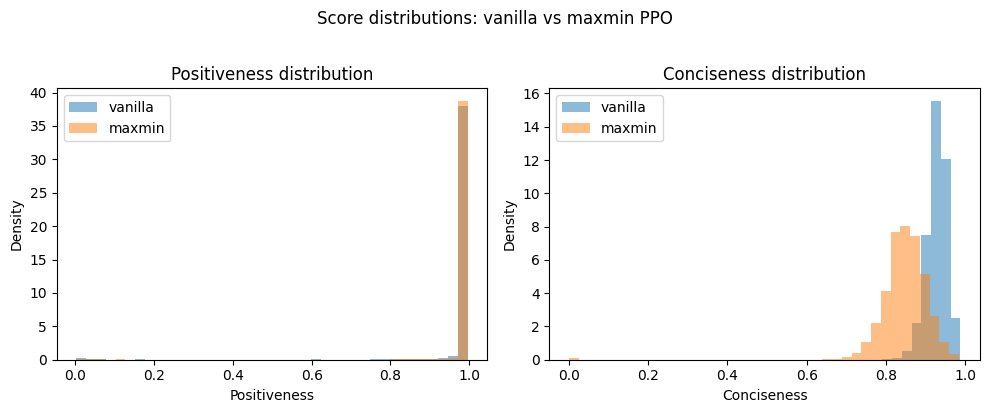

In [7]:
# PPO eval dataset naming (match evaluate_ppo_policy.sh)
PPO_SEED = 42
PPO_PROPORTION = 0.2
PPO_ALPHA = 1.0
DIVISOR_PPO = 250  # same as DIVISOR for normalized_length -> conciseness = 1 - normalized_length

def _ppo_eval_id(method):
    return f"{USER_ID}/{method}-imdb-ppo-eval-prop{PPO_PROPORTION}-alpha{PPO_ALPHA}-seed{PPO_SEED}"

results = {}
for method in ["vanilla", "maxmin"]:
    try:
        data = load_dataset(_ppo_eval_id(method))
        split = list(data.keys())[0] if hasattr(data, "keys") else "train"
        ds_ppo = data[split] if hasattr(data, "keys") else data
        df_ppo = ds_ppo.to_pandas()
    except Exception as e:
        print(f"Could not load {method} PPO eval dataset: {e}")
        print("  Run: ./scripts/evaluate_ppo_policy.sh (generate + score) to create them.")
        continue

    # Score if needed (only prompt + completion)
    if "positiveness" not in df_ppo.columns or "length" not in df_ppo.columns:
        import torch
        from transformers import AutoTokenizer, AutoModelForSequenceClassification
        model_name = "lvwerra/distilbert-imdb"
        tokenizer = AutoTokenizer.from_pretrained(model_name)
        model = AutoModelForSequenceClassification.from_pretrained(model_name)
        model.eval()
        pos_id = model.config.label2id["POSITIVE"]
        positiveness_list = []
        length_list = []
        batch_size = 64
        texts = df_ppo["completion"].astype(str).tolist()
        for i in range(0, len(texts), batch_size):
            batch = texts[i : i + batch_size]
            enc = tokenizer(batch, padding=True, truncation=True, max_length=512, return_tensors="pt")
            with torch.no_grad():
                out = model(**enc)
            probs = torch.softmax(out.logits, dim=-1)
            positiveness_list.extend(probs[:, pos_id].tolist())
            length_list.extend(enc["attention_mask"].sum(dim=1).tolist())
        df_ppo["positiveness"] = positiveness_list
        df_ppo["length"] = length_list

    df_ppo["normalized_length"] = np.clip(df_ppo["length"].astype(float) / DIVISOR_PPO, 0, 1)
    df_ppo["conciseness"] = 1 - df_ppo["normalized_length"]
    results[method] = df_ppo

if not results:
    print("No PPO eval data loaded. Skipping analysis.")
else:
    # Summary table
    print("Conciseness and positiveness: vanilla vs maxmin PPO policies")
    print("=" * 70)
    rows = []
    for method, d in results.items():
        rows.append({
            "method": method,
            "n": len(d),
            "mean_positiveness": d["positiveness"].mean(),
            "std_positiveness": d["positiveness"].std(),
            "mean_conciseness": d["conciseness"].mean(),
            "std_conciseness": d["conciseness"].std(),
        })
    summary = pd.DataFrame(rows)
    print(summary.to_string(index=False))
    print()

    # Bar plot: mean positiveness and mean conciseness
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    x = np.arange(len(results))
    width = 0.35
    methods = list(results.keys())
    axes[0].bar(x - width/2, [results[m]["positiveness"].mean() for m in methods], width, label="mean positiveness", color=["C0", "C1"])
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(methods)
    axes[0].set_ylabel("Mean positiveness")
    axes[0].set_title("Positiveness (sentiment)")
    axes[0].legend()

    axes[1].bar(x - width/2, [results[m]["conciseness"].mean() for m in methods], width, label="mean conciseness", color=["C0", "C1"])
    axes[1].set_xticks(x)
    axes[1].set_xticklabels(methods)
    axes[1].set_ylabel("Mean conciseness (1 - normalized_length)")
    axes[1].set_title("Conciseness")
    axes[1].legend()
    fig.suptitle(f"Vanilla vs MaxMin PPO policies (prop={PPO_PROPORTION}, α={PPO_ALPHA}, seed={PPO_SEED})", y=1.02)
    plt.tight_layout()
    plt.show()

    # Optional: KDE of positiveness and conciseness per policy
    fig2, axes2 = plt.subplots(1, 2, figsize=(10, 4))
    for method, d in results.items():
        axes2[0].hist(d["positiveness"], bins=40, alpha=0.5, label=method, density=True)
        axes2[1].hist(d["conciseness"], bins=40, alpha=0.5, label=method, density=True)
    axes2[0].set_xlabel("Positiveness")
    axes2[0].set_ylabel("Density")
    axes2[0].set_title("Positiveness distribution")
    axes2[0].legend()
    axes2[1].set_xlabel("Conciseness")
    axes2[1].set_ylabel("Density")
    axes2[1].set_title("Conciseness distribution")
    axes2[1].legend()
    fig2.suptitle("Score distributions: vanilla vs maxmin PPO", y=1.02)
    plt.tight_layout()
    plt.show()

### 4.1 Batch minority/majority mean score and worst-group selection frequency (MaxMin PPO)

For a **maxmin** PPO run, training logs to WandB the batch mean reward per group and which group was selected as worst each step. Below we fetch a run's history and plot:
1. **Batch minority and majority mean score** over training steps.
2. **Frequency** that each group (minority vs majority) was selected as the worst group.

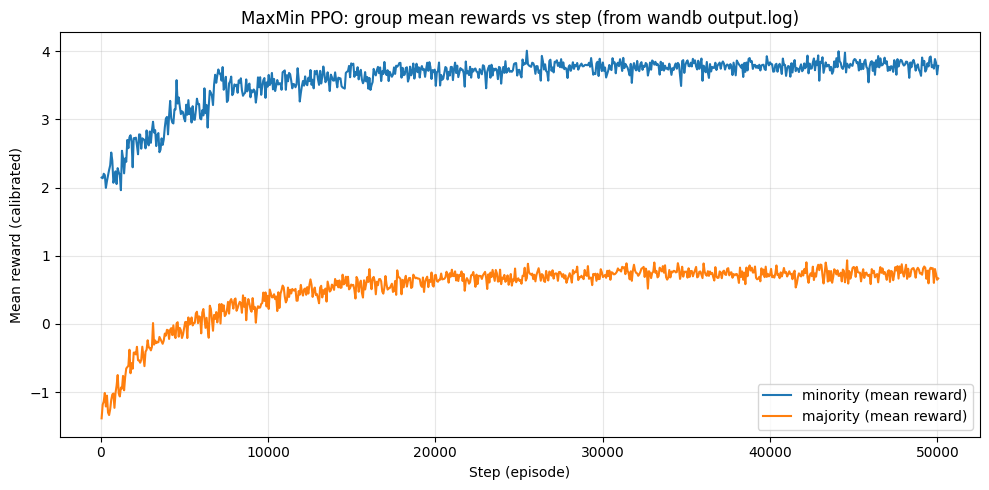

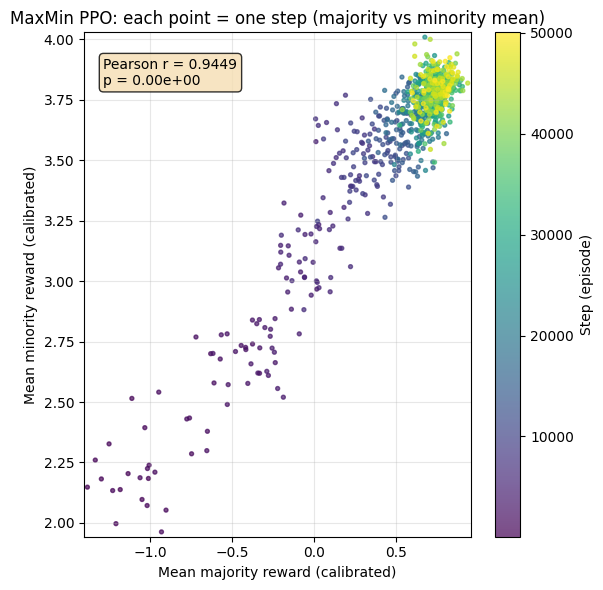

In [9]:
# Plot group mean rewards vs step from the same wandb run output.log
import re
from pathlib import Path
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
PROPORTION = 0.2
ALPHA = 1.0
SEED = 42

# Resolve project root (same logic as previous cell)
def _find_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / "src" / "imdb").exists() and (p / "notebooks").exists():
            return p
    return start
project_root = _find_root(Path.cwd())
wandb_dir = project_root / "wandb"
maxmin_model_id = f"{USER_ID}/maxmin-imdb-ppo-prop{PROPORTION}-alpha{ALPHA}-seed{SEED}"
candidates = []
for cfg in wandb_dir.glob("run-*/files/config.yaml"):
    try:
        if maxmin_model_id in cfg.read_text(errors="ignore"):
            candidates.append(cfg)
    except Exception:
        continue
if not candidates:
    print("No matching wandb run; skip plot.")
else:
    candidates.sort(key=lambda p: p.stat().st_mtime, reverse=True)
    run_dir = candidates[0].parents[1]
    log_path = run_dir / "files" / "output.log"
    if not log_path.exists():
        print("output.log not found; skip plot.")
    else:
        text = log_path.read_text(errors="ignore")
        # Parse each log line that looks like a dict: episode, mean_reward_minority, mean_reward_majority
        episode_pat = re.compile(r"'episode':\s*(\d+)")
        epoch_pat = re.compile(r"'epoch':\s*'([^']+)'")
        mean_min_pat = re.compile(r"'group_selection/mean_reward_minority':\s*'([^']+)'")
        mean_maj_pat = re.compile(r"'group_selection/mean_reward_majority':\s*'([^']+)'")
        steps, epochs, mean_min, mean_maj = [], [], [], []
        for line in text.split("\n"):
            if "group_selection/mean_reward_minority" not in line:
                continue
            ep = episode_pat.search(line)
            epo = epoch_pat.search(line)
            mmin = mean_min_pat.search(line)
            mmaj = mean_maj_pat.search(line)
            if ep and mmin and mmaj:
                steps.append(int(ep.group(1)))
                mean_min.append(float(mmin.group(1)))
                mean_maj.append(float(mmaj.group(1)))
                if epo:
                    try:
                        epochs.append(float(epo.group(1)))
                    except ValueError:
                        epochs.append(len(steps) - 1)
        if steps:
            fig, ax = plt.subplots(figsize=(10, 5))
            ax.plot(steps, mean_min, label="minority (mean reward)", color="C0")
            ax.plot(steps, mean_maj, label="majority (mean reward)", color="C1")
            ax.set_xlabel("Step (episode)")
            ax.set_ylabel("Mean reward (calibrated)")
            ax.set_title("MaxMin PPO: group mean rewards vs step (from wandb output.log)")
            ax.legend()
            ax.grid(True, alpha=0.3)
            plt.tight_layout()
            plt.show()
            # Scatter: x = majority mean, y = minority mean (one point per training step)
            r_pearson, p_pearson = pearsonr(mean_maj, mean_min)
            fig2, ax2 = plt.subplots(figsize=(6, 6))
            sc = ax2.scatter(mean_maj, mean_min, c=steps, cmap="viridis", s=8, alpha=0.7)
            ax2.set_xlabel("Mean majority reward (calibrated)")
            ax2.set_ylabel("Mean minority reward (calibrated)")
            ax2.set_title("MaxMin PPO: each point = one step (majority vs minority mean)")
            ax2.text(0.05, 0.95, f"Pearson r = {r_pearson:.4f}\np = {p_pearson:.2e}", transform=ax2.transAxes, fontsize=10, verticalalignment="top", bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.8))
            ax2.plot([0, 1], [0, 1], "k--", alpha=0.5, label="y=x")
            ax2.set_xlim(min(mean_maj)-0.02, max(mean_maj)+0.02)
            ax2.set_ylim(min(mean_min)-0.02, max(mean_min)+0.02)
            ax2.grid(True, alpha=0.3)
            plt.colorbar(sc, ax=ax2, label="Step (episode)")
            plt.tight_layout()
            plt.show()
        else:
            print("No group_selection/mean_reward lines found in output.log")